
# NASA Kepler Exoplanet Data Analysis 🪐

## Project Overview

This project explores NASA Kepler exoplanet candidate data using Python.

The goal is to analyze planetary candidate characteristics, explore data quality, visualize distributions, and investigate relationships between selected variables.

## Tools and Libraries

- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn

## Dataset

The dataset used in this project is the Kepler Exoplanet Search Results dataset, stored in `cumulative.csv`.

## Main Objectives

- Explore and summarize the dataset.
- Identify missing values and extreme observations.
- Visualize planetary radius distributions.
- Compare KOI scores across disposition categories.
- Explore the relationship between orbital period and planetary radius.

## Project Setup 🔬
Import the required libraries and initialize the project.


In [1]:
print("Science Data Analyzer Project started successfully! 🔬")

Science Data Analyzer Project started successfully! 🔬


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully! 🪐")

Libraries imported successfully! 🪐


## 1. Data Loading and Exploration 📂


In [3]:
df = pd.read_csv(
    "/kaggle/input/datasets/nasa/kepler-exoplanet-search-results/cumulative.csv"
)

print("Dataset loaded successfully! 🪐")

Dataset loaded successfully! 🪐


## 2. Data Quality and Statistical Analysis 🔎


In [4]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

Dataset shape: (9564, 50)

Column names:
['rowid', 'kepid', 'kepoi_name', 'kepler_name', 'koi_disposition', 'koi_pdisposition', 'koi_score', 'koi_fpflag_nt', 'koi_fpflag_ss', 'koi_fpflag_co', 'koi_fpflag_ec', 'koi_period', 'koi_period_err1', 'koi_period_err2', 'koi_time0bk', 'koi_time0bk_err1', 'koi_time0bk_err2', 'koi_impact', 'koi_impact_err1', 'koi_impact_err2', 'koi_duration', 'koi_duration_err1', 'koi_duration_err2', 'koi_depth', 'koi_depth_err1', 'koi_depth_err2', 'koi_prad', 'koi_prad_err1', 'koi_prad_err2', 'koi_teq', 'koi_teq_err1', 'koi_teq_err2', 'koi_insol', 'koi_insol_err1', 'koi_insol_err2', 'koi_model_snr', 'koi_tce_plnt_num', 'koi_tce_delivname', 'koi_steff', 'koi_steff_err1', 'koi_steff_err2', 'koi_slogg', 'koi_slogg_err1', 'koi_slogg_err2', 'koi_srad', 'koi_srad_err1', 'koi_srad_err2', 'ra', 'dec', 'koi_kepmag']

First 5 rows:


,rowid,kepid,kepoi_name,kepler_name,koi_disposition,koi_pdisposition,koi_score,koi_fpflag_nt,koi_fpflag_ss,koi_fpflag_co,...,koi_steff_err2,koi_slogg,koi_slogg_err1,koi_slogg_err2,koi_srad,koi_srad_err1,koi_srad_err2,ra,dec,koi_kepmag
0,1,10797460,K00752.01,Kepler-227 b,CONFIRMED,CANDIDATE,1.000,0,0,0,...,-81.0,4.467,0.064,-0.096,0.927,0.105,-0.061,291.93423,48.141651,15.347
1,2,10797460,K00752.02,Kepler-227 c,CONFIRMED,CANDIDATE,0.969,0,0,0,...,-81.0,4.467,0.064,-0.096,0.927,0.105,-0.061,291.93423,48.141651,15.347
2,3,10811496,K00753.01,NaN,FALSE POSITIVE,FALSE POSITIVE,0.000,0,1,0,...,-176.0,4.544,0.044,-0.176,0.868,0.233,-0.078,297.00482,48.134129,15.436
3,4,10848459,K00754.01,NaN,FALSE POSITIVE,FALSE POSITIVE,0.000,0,1,0,...,-174.0,4.564,0.053,-0.168,0.791,0.201,-0.067,285.53461,48.285210,15.597
4,5,10854555,K00755.01,Kepler-664 b,CONFIRMED,CANDIDATE,1.000,0,0,0,...,-211.0,4.438,0.070,-0.210,1.046,0.334,-0.133,288.75488,48.226200,15.509


In [5]:
print("Data types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

Data types:
rowid                  int64
kepid                  int64
kepoi_name            object
kepler_name           object
koi_disposition       object
koi_pdisposition      object
koi_score            float64
koi_fpflag_nt          int64
koi_fpflag_ss          int64
koi_fpflag_co          int64
koi_fpflag_ec          int64
koi_period           float64
koi_period_err1      float64
koi_period_err2      float64
koi_time0bk          float64
koi_time0bk_err1     float64
koi_time0bk_err2     float64
koi_impact           float64
koi_impact_err1      float64
koi_impact_err2      float64
koi_duration         float64
koi_duration_err1    float64
koi_duration_err2    float64
koi_depth            float64
koi_depth_err1       float64
koi_depth_err2       float64
koi_prad             float64
koi_prad_err1        float64
koi_prad_err2        float64
koi_teq              float64
koi_teq_err1         float64
koi_teq_err2         float64
koi_insol            float64
koi_insol_err1       float64
ko

In [6]:
# Remove columns that contain no data
df = df.drop(columns=["koi_teq_err1", "koi_teq_err2"])

print("Updated dataset shape:", df.shape)

Updated dataset shape: (9564, 48)


## 3. Disposition Overview 🪐


In [7]:
print("Planet disposition counts:")
print(df["koi_disposition"].value_counts())

print("\nPlanet disposition percentages:")
print(df["koi_disposition"].value_counts(normalize=True) * 100)

Planet disposition counts:
koi_disposition
FALSE POSITIVE    5023
CONFIRMED         2293
CANDIDATE         2248
Name: count, dtype: int64

Planet disposition percentages:
koi_disposition
FALSE POSITIVE    52.519866
CONFIRMED         23.975324
CANDIDATE         23.504810
Name: proportion, dtype: float64


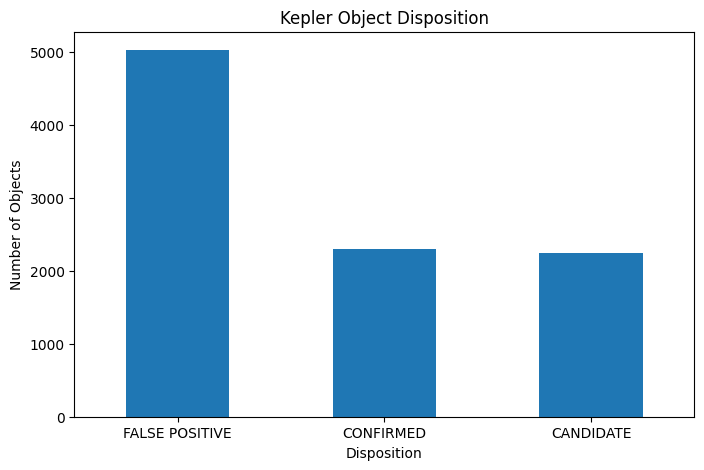

In [8]:
import matplotlib.pyplot as plt

disposition_counts = df["koi_disposition"].value_counts()

plt.figure(figsize=(8, 5))
disposition_counts.plot(kind="bar")

plt.title("Kepler Object Disposition")
plt.xlabel("Disposition")
plt.ylabel("Number of Objects")
plt.xticks(rotation=0)

plt.show()

## 4. Planetary Radius Analysis 📏


In [9]:
print("Planetary radius statistics:")
print(df["koi_prad"].describe())

Planetary radius statistics:
count      9201.000000
mean        102.891778
std        3077.639126
min           0.080000
25%           1.400000
50%           2.390000
75%          14.930000
max      200346.000000
Name: koi_prad, dtype: float64


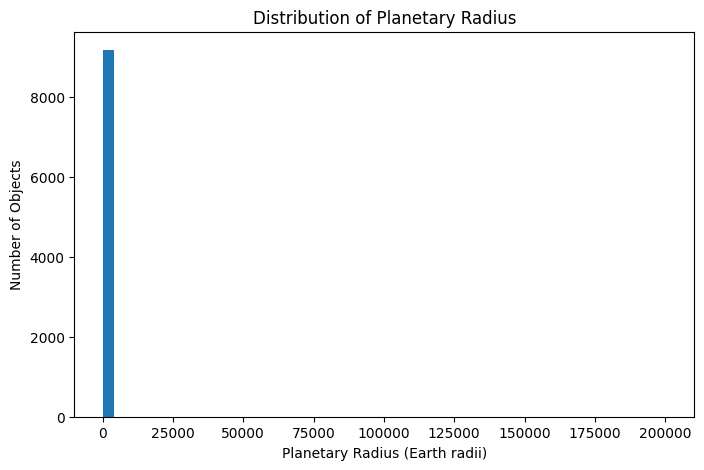

In [10]:
plt.figure(figsize=(8, 5))

plt.hist(df["koi_prad"].dropna(), bins=50)

plt.title("Distribution of Planetary Radius")
plt.xlabel("Planetary Radius (Earth radii)")
plt.ylabel("Number of Objects")

plt.show()

In [11]:
Q1 = df["koi_prad"].quantile(0.25)
Q3 = df["koi_prad"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Upper bound:", upper_bound)

print("\nNumber of extreme values:")
print((df["koi_prad"] > upper_bound).sum())

Q1: 1.4
Q3: 14.93
IQR: 13.53
Upper bound: 35.224999999999994

Number of extreme values:
1469


In [12]:
normal_radius = df.loc[df["koi_prad"] <= upper_bound, "koi_prad"]

print("Original data:")
print(df["koi_prad"].describe())

print("\nWithout extreme values:")
print(normal_radius.describe())

Original data:
count      9201.000000
mean        102.891778
std        3077.639126
min           0.080000
25%           1.400000
50%           2.390000
75%          14.930000
max      200346.000000
Name: koi_prad, dtype: float64

Without extreme values:
count    7732.000000
mean        4.994763
std         7.525569
min         0.080000
25%         1.290000
50%         2.030000
75%         3.510000
max        35.220000
Name: koi_prad, dtype: float64


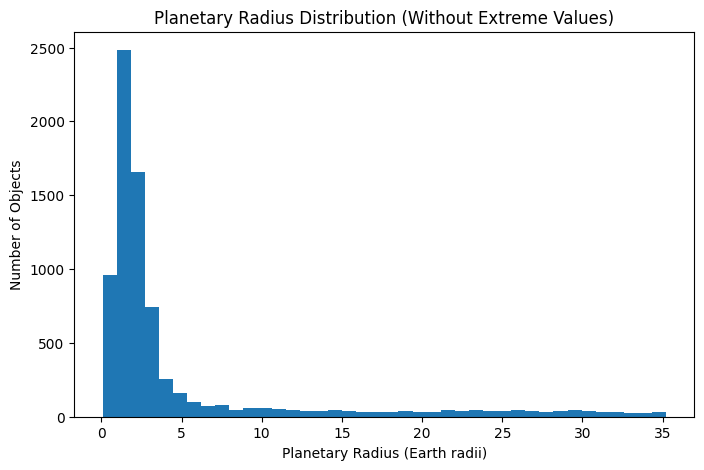

In [13]:
plt.figure(figsize=(8, 5))

plt.hist(normal_radius, bins=40)

plt.title("Planetary Radius Distribution (Without Extreme Values)")
plt.xlabel("Planetary Radius (Earth radii)")
plt.ylabel("Number of Objects")

plt.show()

In [14]:
print(df.groupby("koi_disposition")["koi_prad"].median())

koi_disposition
CANDIDATE         1.78
CONFIRMED         2.17
FALSE POSITIVE    6.85
Name: koi_prad, dtype: float64


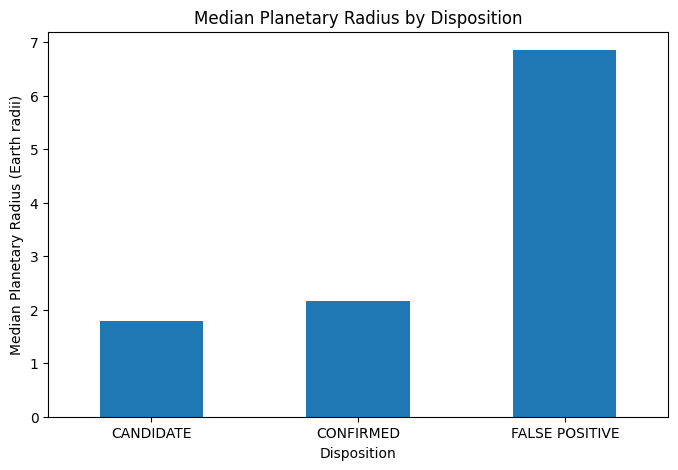

In [15]:
median_radius = df.groupby("koi_disposition")["koi_prad"].median()

plt.figure(figsize=(8, 5))
median_radius.plot(kind="bar")

plt.title("Median Planetary Radius by Disposition")
plt.xlabel("Disposition")
plt.ylabel("Median Planetary Radius (Earth radii)")
plt.xticks(rotation=0)

plt.show()

## 5. Equilibrium Temperature and Orbital Period 🌡️


In [16]:
print(df.groupby("koi_disposition")["koi_teq"].median())

koi_disposition
CANDIDATE          772.0
CONFIRMED          781.0
FALSE POSITIVE    1095.0
Name: koi_teq, dtype: float64


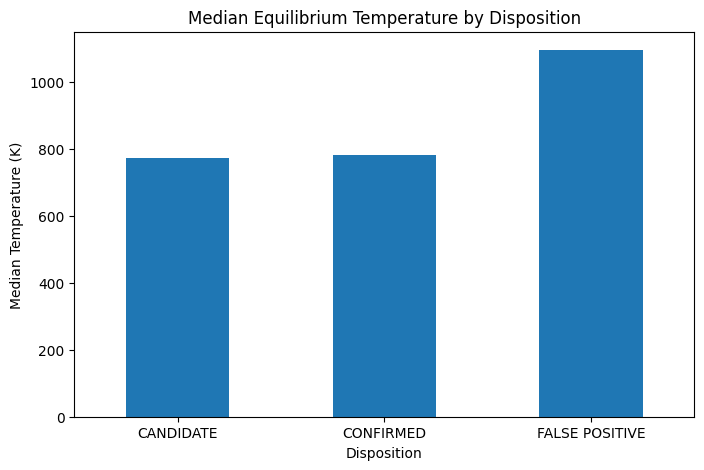

In [17]:
median_temp = df.groupby("koi_disposition")["koi_teq"].median()

plt.figure(figsize=(8, 5))
median_temp.plot(kind="bar")

plt.title("Median Equilibrium Temperature by Disposition")
plt.xlabel("Disposition")
plt.ylabel("Median Temperature (K)")
plt.xticks(rotation=0)

plt.show()

In [18]:
print(df.groupby("koi_disposition")["koi_period"].median())

koi_disposition
CANDIDATE         13.278651
CONFIRMED         11.322697
FALSE POSITIVE     6.383157
Name: koi_period, dtype: float64


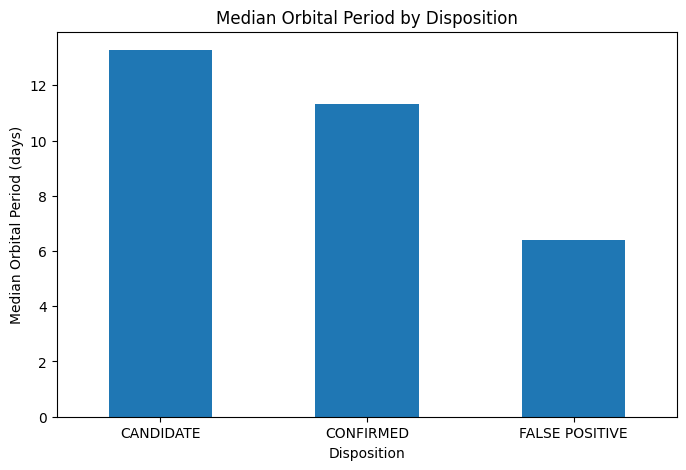

In [19]:
median_period = df.groupby("koi_disposition")["koi_period"].median()

plt.figure(figsize=(8, 5))
median_period.plot(kind="bar")

plt.title("Median Orbital Period by Disposition")
plt.xlabel("Disposition")
plt.ylabel("Median Orbital Period (days)")
plt.xticks(rotation=0)

plt.show()

## 6. Radius vs Equilibrium Temperature 📈


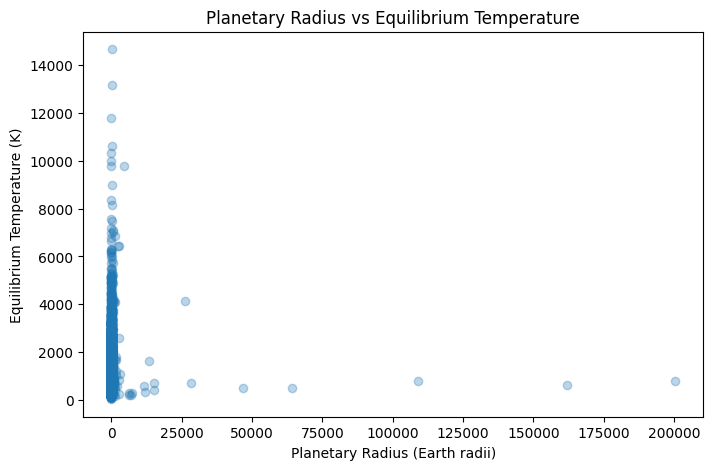

In [20]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df["koi_prad"],
    df["koi_teq"],
    alpha=0.3
)

plt.title("Planetary Radius vs Equilibrium Temperature")
plt.xlabel("Planetary Radius (Earth radii)")
plt.ylabel("Equilibrium Temperature (K)")

plt.show()

In [21]:
correlation = df["koi_prad"].corr(df["koi_teq"])

print("Correlation between Planetary Radius and Equilibrium Temperature:")
print(correlation)

Correlation between Planetary Radius and Equilibrium Temperature:
-0.0012490349579592822


## 7. Missing Data Investigation 🔍


In [22]:
missing_percent = df[[
    "koi_prad",
    "koi_teq",
    "koi_period",
    "koi_score"
]].isnull().mean() * 100

print("Missing values in important variables:")
print(missing_percent)

Missing values in important variables:
koi_prad       3.795483
koi_teq        3.795483
koi_period     0.000000
koi_score     15.788373
dtype: float64


In [23]:
print("Missing values overlap:")

print(
    df[["koi_prad", "koi_teq"]]
    .isnull()
    .sum(axis=1)
    .value_counts()
)

Missing values overlap:
0    9201
2     363
Name: count, dtype: int64


## 8. KOI Score Analysis ⭐


In [24]:
import pandas as pd

df = pd.read_csv(
    "/kaggle/input/datasets/nasa/kepler-exoplanet-search-results/cumulative.csv"
)

df = df.drop(columns=["koi_teq_err1", "koi_teq_err2"])

print("Dataset loaded successfully! 🪐")
print("Shape:", df.shape)

Dataset loaded successfully! 🪐
Shape: (9564, 48)


In [25]:
print("KOI score statistics:")
print(df["koi_score"].describe())

KOI score statistics:
count    8054.000000
mean        0.480829
std         0.476928
min         0.000000
25%         0.000000
50%         0.334000
75%         0.998000
max         1.000000
Name: koi_score, dtype: float64


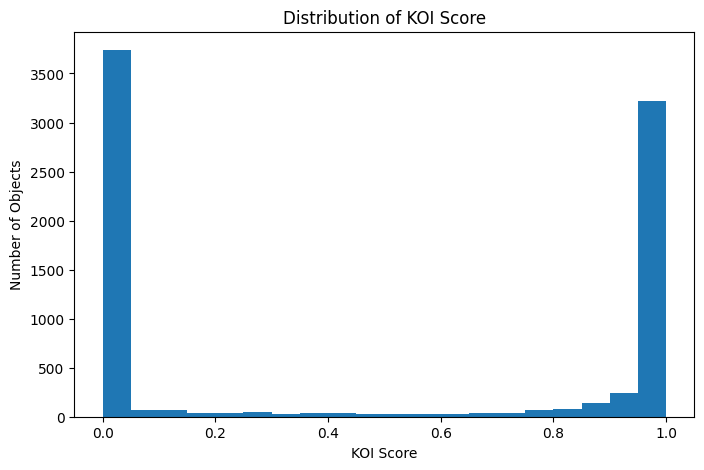

In [26]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.hist(df["koi_score"].dropna(), bins=20)

plt.title("Distribution of KOI Score")
plt.xlabel("KOI Score")
plt.ylabel("Number of Objects")

plt.show()

In [27]:
median_score = df.groupby("koi_disposition")["koi_score"].median()

print("Median KOI Score by Disposition:")
print(median_score)

Median KOI Score by Disposition:
koi_disposition
CANDIDATE         0.987
CONFIRMED         1.000
FALSE POSITIVE    0.000
Name: koi_score, dtype: float64


Median KOI Score by Disposition:
koi_disposition
CANDIDATE         0.987
CONFIRMED         1.000
FALSE POSITIVE    0.000
Name: koi_score, dtype: float64


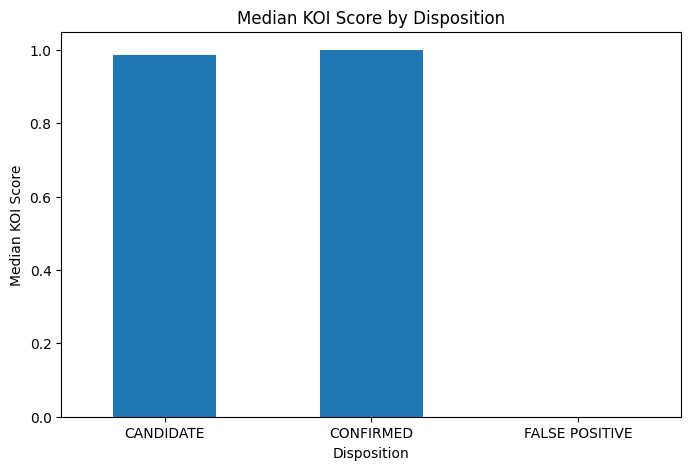

In [28]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv(
    "/kaggle/input/datasets/nasa/kepler-exoplanet-search-results/cumulative.csv"
)

df = df.drop(columns=["koi_teq_err1", "koi_teq_err2"])

median_score = df.groupby("koi_disposition")["koi_score"].median()

print("Median KOI Score by Disposition:")
print(median_score)

plt.figure(figsize=(8, 5))

median_score.plot(kind="bar")

plt.title("Median KOI Score by Disposition")
plt.xlabel("Disposition")
plt.ylabel("Median KOI Score")
plt.xticks(rotation=0)

plt.show()

## 9. KOI Score vs Planetary Radius 📊


In [29]:
import pandas as pd

df = pd.read_csv(
    "/kaggle/input/datasets/nasa/kepler-exoplanet-search-results/cumulative.csv"
)

correlation_score_radius = df["koi_score"].corr(df["koi_prad"])

print("Correlation between KOI Score and Planetary Radius:")
print(correlation_score_radius)

Correlation between KOI Score and Planetary Radius:
-0.07687022031633721


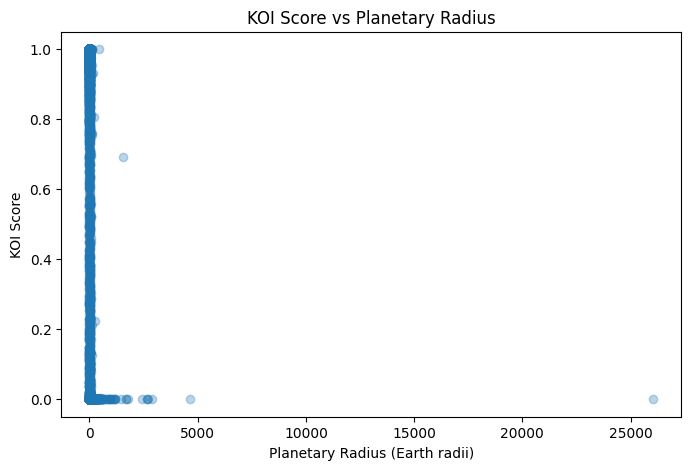

In [30]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(
    df["koi_prad"],
    df["koi_score"],
    alpha=0.3
)

plt.title("KOI Score vs Planetary Radius")
plt.xlabel("Planetary Radius (Earth radii)")
plt.ylabel("KOI Score")

plt.show()

In [31]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv(
    "/kaggle/input/datasets/nasa/kepler-exoplanet-search-results/cumulative.csv"
)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print(df[["koi_prad", "koi_score"]].head())

Dataset loaded successfully!
Dataset shape: (9564, 50)
   koi_prad  koi_score
0      2.26      1.000
1      2.83      0.969
2     14.60      0.000
3     33.46      0.000
4      2.75      1.000


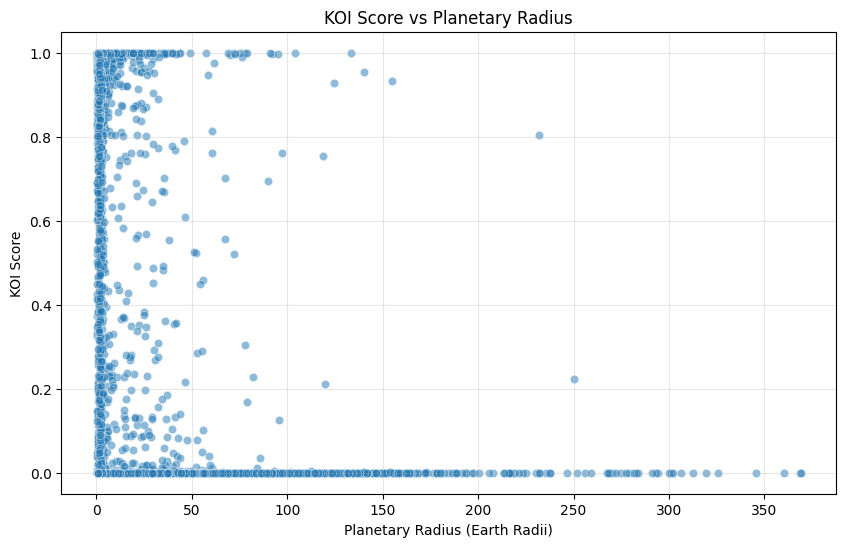

Original rows: 9564
Rows displayed: 7926


In [32]:
plot_df = df[
    (df["koi_prad"] > 0) &
    (df["koi_prad"] <= df["koi_prad"].quantile(0.99)) &
    (df["koi_score"].notna())
].copy()

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=plot_df,
    x="koi_prad",
    y="koi_score",
    alpha=0.5
)

plt.title("KOI Score vs Planetary Radius")
plt.xlabel("Planetary Radius (Earth Radii)")
plt.ylabel("KOI Score")
plt.grid(True, alpha=0.3)
plt.show()

print("Original rows:", len(df))
print("Rows displayed:", len(plot_df))

In [33]:
# Basic statistical analysis

print("Dataset shape:", df.shape)

print("\nMissing values:")
print(df[["koi_prad", "koi_score"]].isnull().sum())

print("\nStatistical summary:")
display(df[["koi_prad", "koi_score"]].describe())

Dataset shape: (9564, 50)

Missing values:
koi_prad      363
koi_score    1510
dtype: int64

Statistical summary:


,koi_prad,koi_score
count,9201.000000,8054.000000
mean,102.891778,0.480829
std,3077.639126,0.476928
min,0.080000,0.000000
25%,1.400000,0.000000
50%,2.390000,0.334000
75%,14.930000,0.998000
max,200346.000000,1.000000


In [34]:
# Investigating extreme values

radius = df["koi_prad"].dropna()

print("Radius percentiles:")
print(radius.quantile([0.50, 0.90, 0.95, 0.99, 1.00]))

print("\nNumber of candidates with radius > 100:")
print((radius > 100).sum())

print("\nNumber of candidates with radius <= 0:")
print((radius <= 0).sum())

Radius percentiles:
0.50         2.39
0.90        52.84
0.95        87.21
0.99       369.20
1.00    200346.00
Name: koi_prad, dtype: float64

Number of candidates with radius > 100:
370

Number of candidates with radius <= 0:
0


In [35]:
import numpy as np

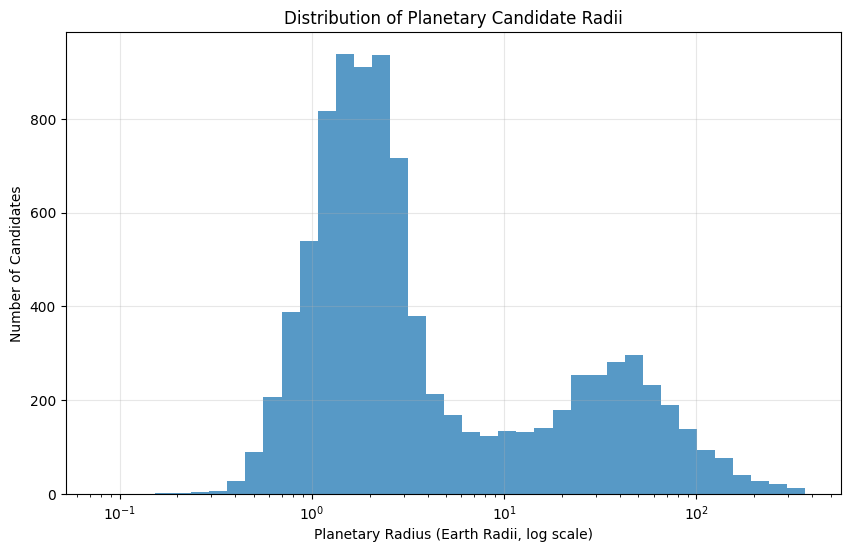

In [36]:
# Visualizing planetary radius distribution

radius = df["koi_prad"].dropna()
radius = radius[radius > 0]

# Keep the central 99% for visualization only
radius_plot = radius[radius <= radius.quantile(0.99)]

bins = np.logspace(
    np.log10(radius_plot.min()),
    np.log10(radius_plot.max()),
    40
)

plt.figure(figsize=(10, 6))

sns.histplot(radius_plot, bins=bins)

plt.xscale("log")
plt.title("Distribution of Planetary Candidate Radii")
plt.xlabel("Planetary Radius (Earth Radii, log scale)")
plt.ylabel("Number of Candidates")
plt.grid(True, alpha=0.3)

plt.show()

## 10. KOI Score by Disposition 📦


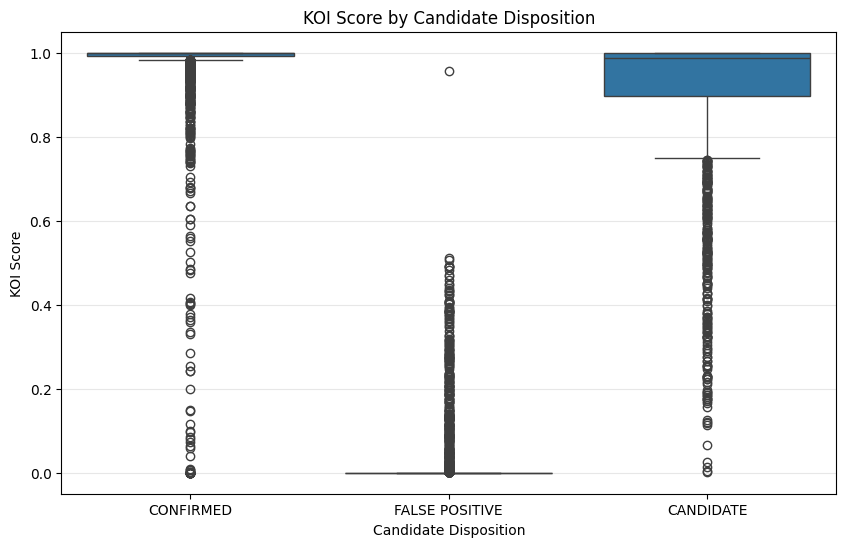

koi_disposition
CANDIDATE         0.987
CONFIRMED         1.000
FALSE POSITIVE    0.000
Name: koi_score, dtype: float64


In [37]:
# Compare KOI Score across candidate dispositions

score_df = df[
    df["koi_score"].notna() &
    df["koi_disposition"].notna()
].copy()

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=score_df,
    x="koi_disposition",
    y="koi_score"
)

plt.title("KOI Score by Candidate Disposition")
plt.xlabel("Candidate Disposition")
plt.ylabel("KOI Score")
plt.grid(True, axis="y", alpha=0.3)
plt.show()

print(
    score_df.groupby("koi_disposition")["koi_score"]
    .median()
)

## 11. Disposition Category Analysis 📉


Number of objects in each category:
koi_disposition
FALSE POSITIVE    5023
CONFIRMED         2293
CANDIDATE         2248
Name: count, dtype: int64


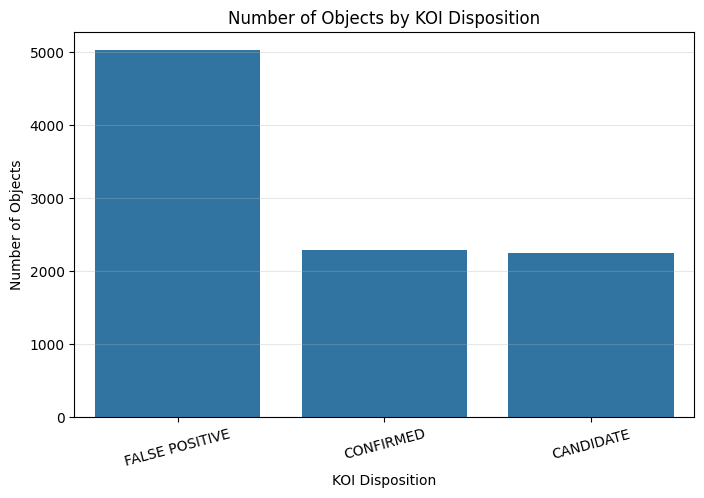

In [38]:
# Count candidates in each disposition category

disposition_counts = df["koi_disposition"].value_counts()

print("Number of objects in each category:")
print(disposition_counts)

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="koi_disposition",
    order=disposition_counts.index
)

plt.title("Number of Objects by KOI Disposition")
plt.xlabel("KOI Disposition")
plt.ylabel("Number of Objects")
plt.xticks(rotation=15)
plt.grid(True, axis="y", alpha=0.3)
plt.show()

In [39]:
print(df["koi_disposition"].value_counts())

koi_disposition
FALSE POSITIVE    5023
CONFIRMED         2293
CANDIDATE         2248
Name: count, dtype: int64


Percentage of each category:
koi_disposition
FALSE POSITIVE    52.52
CONFIRMED         23.98
CANDIDATE         23.50
Name: proportion, dtype: float64


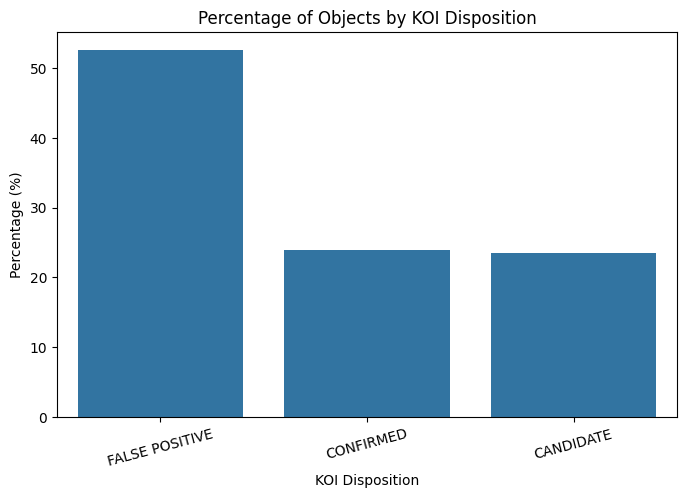

In [40]:
# Calculate the percentage of each disposition

disposition_percent = (
    df["koi_disposition"].value_counts(normalize=True) * 100
)

print("Percentage of each category:")
print(disposition_percent.round(2))

plt.figure(figsize=(8, 5))

sns.barplot(
    x=disposition_percent.index,
    y=disposition_percent.values
)

plt.title("Percentage of Objects by KOI Disposition")
plt.xlabel("KOI Disposition")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=15)
plt.show()

## 12. Orbital Period vs Planetary Radius 🌌


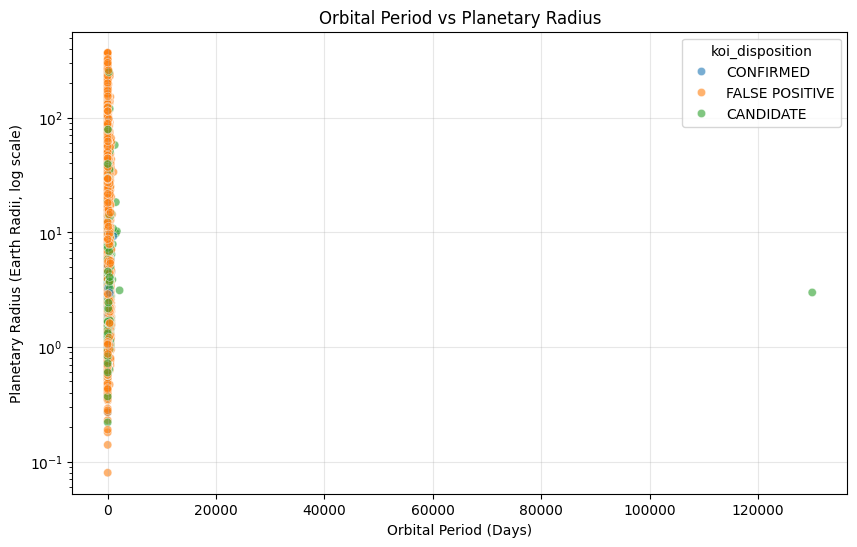

Rows displayed: 9109


In [41]:
# Orbital Period vs Planetary Radius

period_df = df[
    (df["koi_period"] > 0) &
    (df["koi_prad"] > 0) &
    (df["koi_prad"] <= df["koi_prad"].quantile(0.99))
].copy()

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=period_df,
    x="koi_period",
    y="koi_prad",
    hue="koi_disposition",
    alpha=0.6
)

plt.yscale("log")
plt.title("Orbital Period vs Planetary Radius")
plt.xlabel("Orbital Period (Days)")
plt.ylabel("Planetary Radius (Earth Radii, log scale)")
plt.grid(True, alpha=0.3)
plt.show()

print("Rows displayed:", len(period_df))

In [42]:
# Calculate correlation between orbital period and planetary radius

correlation = period_df["koi_period"].corr(
    period_df["koi_prad"]
)

print("Correlation between Orbital Period and Planetary Radius:")
print(correlation)

Correlation between Orbital Period and Planetary Radius:
-0.011159653276071874



## 13. Key Findings 💡

In this project, we analyzed NASA Kepler exoplanet candidate data.

- The dataset contains 9,564 records and 50 columns.
- False positives represent 52.52% of the records.
- Confirmed objects represent 23.98%, while candidates represent 23.50%.
- The median KOI score differs across disposition categories.
- The Pearson correlation between orbital period and planetary radius is approximately -0.011, indicating almost no linear correlation in this analysis.